# Segmentación de inmuebles en arriendo con K-Means
**Universidad de Cundinamarca – Especialización en Inteligencia Artificial**
Introducción a Machine Learning · Periodo 2026-2 · Docente: Ing. Wilson Rojas Reales, PhD(c)

Adaptación del algoritmo de ejemplo `KMeansSegInmuebles.py` para leer el dataset `DATASET_INmuebles.xlsx` (1 000 inmuebles), segmentar el portafolio con K-Means y comparar `n_clusters = 2, 3 y 4`.

Contenido: (1) carga y calidad de datos, (2) análisis exploratorio, (3) preprocesamiento, (4) selección de *k*, (5) modelos con k = 3, 2 y 4, (6) validación con clustering jerárquico, (7) enfoque propuesto con variables comerciales, (8) exportación de resultados.

## 1. Librerías, utilidades y carga del dataset

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# --- Ubicación del dataset -------------------------------------------------
# En Colab: suba el archivo con el panel de archivos, o reemplace URL_GITHUB por la
# URL "raw" del archivo dentro de su repositorio.
URL_GITHUB = "https://raw.githubusercontent.com/USUARIO/REPOSITORIO/main/data/DATASET_INmuebles.xlsx"
CANDIDATOS = ["data/DATASET_INmuebles.xlsx", "../data/DATASET_INmuebles.xlsx",
              "DATASET_INmuebles.xlsx", "/content/DATASET_INmuebles.xlsx"]
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
RES_DIR = "resultados"; os.makedirs(RES_DIR, exist_ok=True)

def cargar_dataset():
    for ruta in CANDIDATOS:
        if os.path.exists(ruta):
            print("Leyendo:", ruta)
            return pd.read_excel(ruta, sheet_name="Inmuebles_Arriendo")
    try:
        print("Leyendo desde GitHub:", URL_GITHUB)
        return pd.read_excel(URL_GITHUB, sheet_name="Inmuebles_Arriendo")
    except Exception as e:
        print("No se pudo leer desde GitHub:", e)
    from google.colab import files          # último recurso: subir el archivo
    subido = files.upload()
    return pd.read_excel(next(iter(subido)), sheet_name="Inmuebles_Arriendo")

# Nombres limpios (el Excel trae "Antig[uedad" y dos columnas llamadas "Estrato")
RENOMBRAR = {"Inmueble": "ID_inmueble", "Área m²": "Area_m2", "Precio arriendo": "Precio_arriendo",
             "Baños": "Banos", "Antig[uedad": "Antiguedad_anios", "Tipo Inmueble": "Tipo_inmueble",
             "Estrato.1": "Estrato_dup"}
NUM = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]
CAT = ["Localidad", "Tipo_inmueble"]

def crear_preprocesador():
    return ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

def guardar(nombre):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{nombre}.png", dpi=150, bbox_inches="tight"); plt.show()

In [2]:
df_raw = cargar_dataset()
print("Dimensiones originales:", df_raw.shape)
df_raw.head()

Leyendo: data/DATASET_INmuebles.xlsx
Dimensiones originales: (1000, 10)


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


In [3]:
df_raw.info()
print("\nValores nulos por columna:\n", df_raw.isna().sum())
print("\nRegistros duplicados (sin ID):", df_raw.drop(columns="Inmueble").duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Inmueble         1000 non-null   str  
 1   Área m²          1000 non-null   int64
 2   Habitaciones     1000 non-null   int64
 3   Estrato          1000 non-null   int64
 4   Precio arriendo  1000 non-null   int64
 5   Baños            1000 non-null   int64
 6   Antig[uedad      1000 non-null   int64
 7   Localidad        1000 non-null   str  
 8   Tipo Inmueble    1000 non-null   str  
 9   Estrato.1        1000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 78.3 KB

Valores nulos por columna:
 Inmueble           0
Área m²            0
Habitaciones       0
Estrato            0
Precio arriendo    0
Baños              0
Antig[uedad        0
Localidad          0
Tipo Inmueble      0
Estrato.1          0
dtype: int64

Registros duplicados (sin ID): 0


## 2. Calidad de datos

El Excel presenta tres situaciones que hay que resolver antes de modelar:

1. La columna de antigüedad se llama `Antig[uedad` (error de digitación) → se renombra a `Antiguedad_anios`.
2. Existen **dos columnas llamadas `Estrato`** con valores distintos para el mismo inmueble. Pandas renombra la segunda como `Estrato.1`. Se compara cuál es coherente con el resto de variables.
3. Se verifica la relación entre `Localidad` y `Tipo_inmueble`.

In [4]:
df = df_raw.rename(columns=RENOMBRAR)
comp = df[["Precio_arriendo", "Area_m2", "Habitaciones", "Estrato", "Estrato_dup"]].corr().loc[["Estrato", "Estrato_dup"], ["Precio_arriendo", "Area_m2", "Habitaciones"]]
print("Correlación de cada columna 'Estrato' con las variables físicas y económicas:")
display(comp.round(3))
print("Coincidencia entre ambas columnas de estrato:", (df.Estrato == df.Estrato_dup).mean().round(3))
print("\nRangos -> Estrato:", sorted(df.Estrato.unique()), "| Estrato_dup:", sorted(df.Estrato_dup.unique()))
print("\nTabla cruzada Localidad vs Tipo de inmueble:")
display(pd.crosstab(df.Localidad, df.Tipo_inmueble))

Correlación de cada columna 'Estrato' con las variables físicas y económicas:


,Precio_arriendo,Area_m2,Habitaciones
Estrato,0.838,0.822,0.824
Estrato_dup,0.025,0.018,0.036


Coincidencia entre ambas columnas de estrato: 0.167

Rangos -> Estrato: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)] | Estrato_dup: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Tabla cruzada Localidad vs Tipo de inmueble:


Tipo_inmueble,ApartaEstudio,Apto,Casa
Localidad,,,
Chapinero,0,0,333
Suba,0,334,0
Usaquén,333,0,0


**Decisiones:**

- Se conserva la primera columna `Estrato` (rango 2–6, correlación ≈ 0,84 con el precio, coherente con el mercado) y se descarta `Estrato_dup` (rango 1–4, correlación ≈ 0 con precio y área), que se trata como un error de captura.
- `Localidad` y `Tipo_inmueble` tienen una relación 1 a 1 (Suba–Apto, Chapinero–Casa, Usaquén–ApartaEstudio): en la práctica son **la misma información**. Se conservan ambas porque el enunciado las exige, pero se tiene en cuenta en el análisis.
- `ID_inmueble` se conserva para identificar los registros, **pero no se usa para calcular distancias**.

In [5]:
df = df.drop(columns="Estrato_dup")
df[NUM].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Precio_arriendo,1000.0,3633286.7,2438534.3,702480.0,1644060.2,2930804.5,5394807.0,8988836.0
Area_m2,1000.0,96.7,54.1,30.0,55.0,80.5,135.0,220.0
Habitaciones,1000.0,2.7,1.3,1.0,2.0,2.0,4.0,5.0
Banos,1000.0,1.5,0.5,1.0,1.0,1.0,2.0,2.0
Antiguedad_anios,1000.0,8.5,2.3,5.0,6.0,8.5,10.0,12.0
Estrato,1000.0,4.0,1.4,2.0,3.0,4.0,5.0,6.0


## 3. Análisis exploratorio

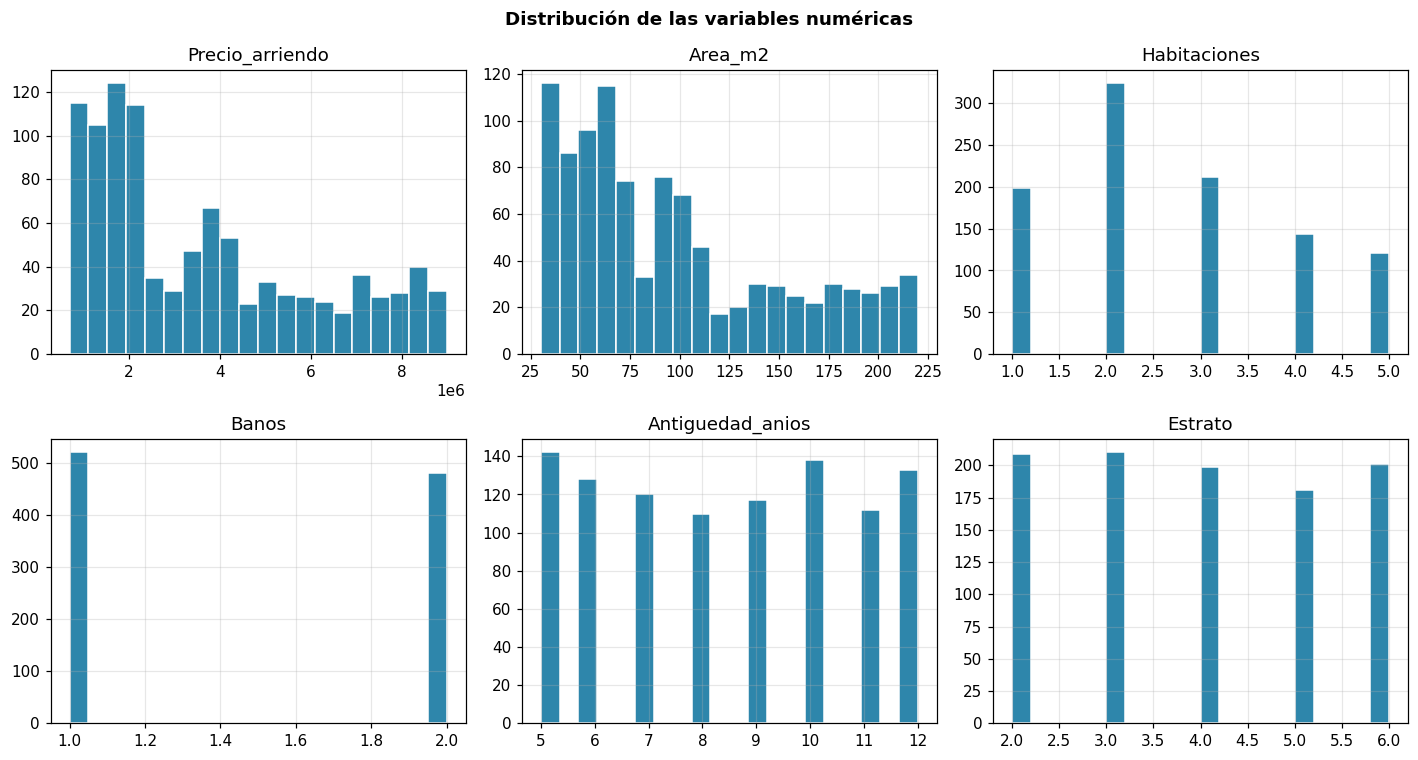

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for a, c in zip(ax.ravel(), NUM):
    a.hist(df[c], bins=20, color="#2E86AB", edgecolor="white"); a.set_title(c)
fig.suptitle("Distribución de las variables numéricas", fontweight="bold")
guardar("01_histogramas")

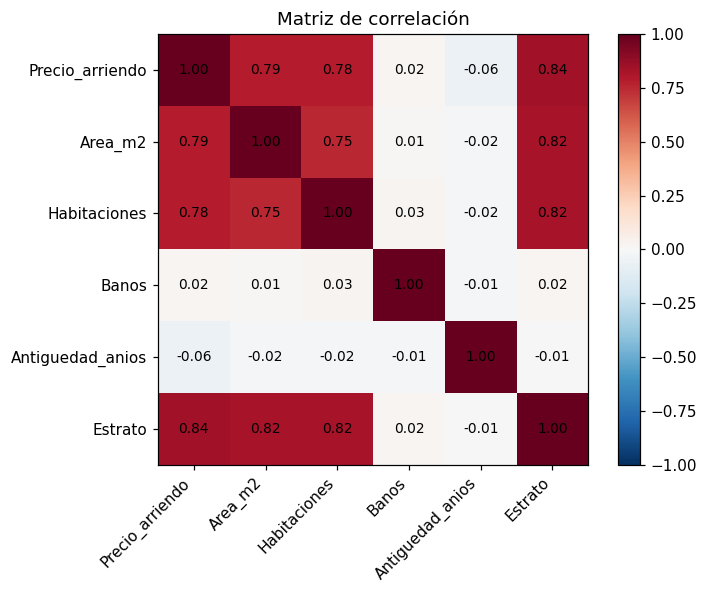

In [7]:
corr = df[NUM].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM))); ax.set_xticklabels(NUM, rotation=45, ha="right")
ax.set_yticks(range(len(NUM))); ax.set_yticklabels(NUM)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im); ax.set_title("Matriz de correlación"); ax.grid(False)
guardar("02_correlacion")

In [8]:
print("Promedios por estrato:")
display(df.groupby("Estrato")[["Precio_arriendo", "Area_m2", "Habitaciones"]].mean().round(0))
print("Promedios por localidad:")
display(df.groupby("Localidad")[["Precio_arriendo", "Area_m2", "Estrato"]].mean().round(1))

Promedios por estrato:


,Precio_arriendo,Area_m2,Habitaciones
Estrato,,,
2,1446739.0,50.0,2.0
3,1491558.0,49.0,2.0
4,3069443.0,85.0,2.0
5,6352920.0,154.0,4.0
6,6253698.0,155.0,4.0


Promedios por localidad:


,Precio_arriendo,Area_m2,Estrato
Localidad,,,
Chapinero,3537593.4,94.9,3.9
Suba,3370335.8,94.1,3.9
Usaquén,3992720.5,101.2,4.1


Precio, área, habitaciones y estrato están fuertemente correlacionados (r entre 0,75 y 0,84): forman un único eje de "tamaño/valor". Baños y antigüedad son prácticamente independientes de todo lo demás. Las tres localidades tienen perfiles muy parecidos.

## 4. Preprocesamiento
Estandarización (media 0, desviación 1) de las 6 variables numéricas y codificación *one-hot* de las 2 categóricas. Sin escalar, el precio (millones de pesos) dominaría por completo la distancia euclidiana.

In [9]:
pre = crear_preprocesador()
X = pre.fit_transform(df[NUM + CAT])
nombres = pre.get_feature_names_out()
print("Columnas en el archivo original:", df_raw.shape[1], "(incluye ID y estrato duplicado)")
print("Variables usadas como características:", len(NUM + CAT))
print("Dimensiones tras el preprocesamiento:", X.shape)
print(list(nombres))

Columnas en el archivo original: 10 (incluye ID y estrato duplicado)
Variables usadas como características: 8
Dimensiones tras el preprocesamiento: (1000, 12)
['num__Precio_arriendo', 'num__Area_m2', 'num__Habitaciones', 'num__Banos', 'num__Antiguedad_anios', 'num__Estrato', 'cat__Localidad_Chapinero', 'cat__Localidad_Suba', 'cat__Localidad_Usaquén', 'cat__Tipo_inmueble_ApartaEstudio', 'cat__Tipo_inmueble_Apto', 'cat__Tipo_inmueble_Casa']


In [10]:
# Ilustración: efecto de NO escalar (el precio domina la distancia)
Xs = pd.get_dummies(df[NUM + CAT]).astype(float).values
l_sin = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Xs)
print("K-Means k=3 SIN escalar – promedios por cluster:")
display(df.assign(c=l_sin).groupby("c")[["Precio_arriendo", "Area_m2", "Estrato"]].agg(["mean", "min", "max"]).round(0))

K-Means k=3 SIN escalar – promedios por cluster:


Precio_arriendo                   Area_m2          Estrato        
             mean      min      max    mean min  max    mean min max
c                                                                   
0       1605203.0   702480  2863027    55.0  30  107     3.0   2   4
1       7491328.0  5864821  8988836   157.0  90  220     6.0   5   6
2       4169639.0  2904801  5772215   122.0  60  220     5.0   4   6

## 5. Selección del número de clusters (método del codo y coeficiente de silueta)

,inercia,silueta,davies_bouldin
k,,,
2,4441.922,0.350,1.207
3,3824.452,0.255,1.539
4,3440.683,0.222,1.851
5,3191.634,0.200,1.788
6,2991.379,0.214,1.803
7,2858.790,0.207,1.757
8,2642.758,0.242,1.605


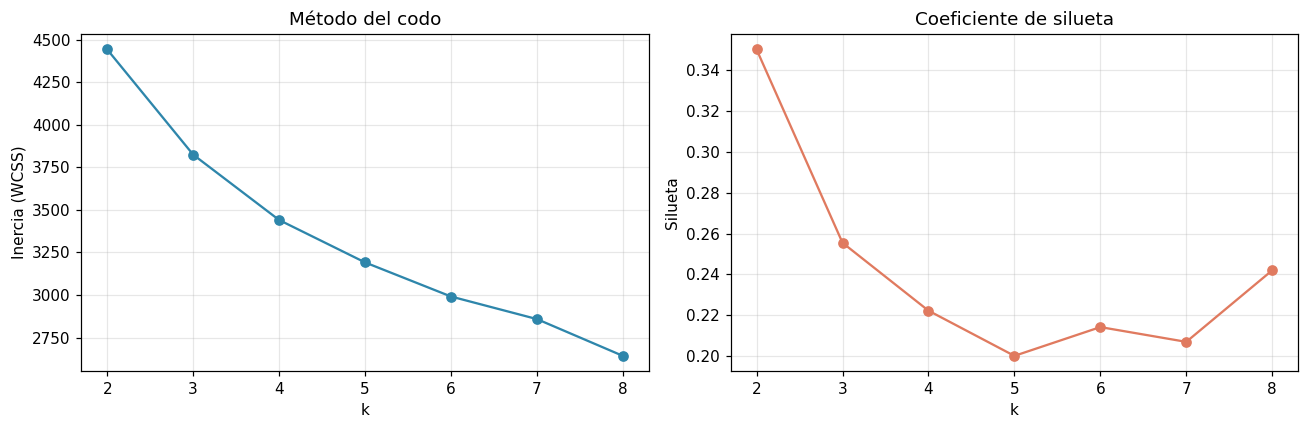

In [11]:
filas = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    filas.append({"k": k, "inercia": m.inertia_, "silueta": silhouette_score(X, m.labels_),
                  "davies_bouldin": davies_bouldin_score(X, m.labels_)})
metricas = pd.DataFrame(filas).set_index("k"); display(metricas.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(metricas.index, metricas.inercia, "o-", color="#2E86AB"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia (WCSS)")
ax[1].plot(metricas.index, metricas.silueta, "o-", color="#E07A5F"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta")
guardar("03_codo_silueta")

## 6. Modelos K-Means: k = 3 (ejemplo), k = 2 y k = 4 (actividad 3)

In [12]:
def entrenar_y_perfilar(k, X=X):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab = modelo.fit_predict(X)
    d = df.assign(cluster=lab)
    perfil = d.groupby("cluster")[NUM].mean().round(1)
    perfil.insert(0, "n", d.groupby("cluster").size())
    perfil["Estrato_min"] = d.groupby("cluster").Estrato.min(); perfil["Estrato_max"] = d.groupby("cluster").Estrato.max()
    perfil["pct_2banos"] = (d.groupby("cluster").Banos.apply(lambda s: (s == 2).mean()) * 100).round(0)
    print(f"=== K-Means k={k} | silueta={silhouette_score(X, lab):.3f} | Davies-Bouldin={davies_bouldin_score(X, lab):.3f}")
    display(perfil)
    print("Distribución por localidad (%):")
    display((pd.crosstab(lab, d.Localidad, normalize="index") * 100).round(0))
    return modelo, lab

modelo3, lab3 = entrenar_y_perfilar(3)

=== K-Means k=3 | silueta=0.255 | Davies-Bouldin=1.539


,n,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,Estrato_min,Estrato_max,pct_2banos
cluster,,,,,,,,,,
0,326,2000101.3,61.3,1.8,1.0,8.6,3.0,2,4,0.0
1,382,6300711.6,154.6,4.0,1.5,8.4,5.5,5,6,49.0
2,292,1967061.1,60.7,1.8,2.0,8.5,3.0,2,4,100.0


Distribución por localidad (%):


Localidad,Chapinero,Suba,Usaquén
row_0,,,
0,34.0,35.0,31.0
1,30.0,31.0,38.0
2,36.0,35.0,29.0


**Interpretación k = 3:** el algoritmo **no** reproduce los tres segmentos del ejercicio de ejemplo (económico / intermedio / premium). Encuentra un grupo *premium* (estrato 5–6) y divide el resto en dos grupos idénticos en precio, área y estrato que solo se diferencian en el número de baños (1 vs 2). Como `Banos` es binaria, al estandarizarla crea dos "bloques" de puntos muy separados que K-Means aprovecha para partir los datos.

In [13]:
modelo2, lab2 = entrenar_y_perfilar(2)   # Actividad 3a: KMeans(n_clusters=2, random_state=42, n_init=10)

=== K-Means k=2 | silueta=0.350 | Davies-Bouldin=1.207


,n,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,Estrato_min,Estrato_max,pct_2banos
cluster,,,,,,,,,,
0,618,1984490.1,61.0,1.8,1.5,8.5,3.0,2,4,47.0
1,382,6300711.6,154.6,4.0,1.5,8.4,5.5,5,6,49.0


Distribución por localidad (%):


Localidad,Chapinero,Suba,Usaquén
row_0,,,
0,35.0,35.0,30.0
1,30.0,31.0,38.0


In [14]:
modelo4, lab4 = entrenar_y_perfilar(4)   # Actividad 3b: KMeans(n_clusters=4, random_state=42, n_init=10)

=== K-Means k=4 | silueta=0.222 | Davies-Bouldin=1.851


,n,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,Estrato_min,Estrato_max,pct_2banos
cluster,,,,,,,,,,
0,326,2000101.3,61.3,1.8,1.0,8.6,3.0,2,4,0.0
1,188,6327014.2,154.3,4.1,2.0,8.4,5.5,5,6,100.0
2,194,6275222.4,154.8,4.0,1.0,8.3,5.5,5,6,0.0
3,292,1967061.1,60.7,1.8,2.0,8.5,3.0,2,4,100.0


Distribución por localidad (%):


Localidad,Chapinero,Suba,Usaquén
row_0,,,
0,34.0,35.0,31.0
1,28.0,31.0,40.0
2,32.0,31.0,37.0
3,36.0,35.0,29.0


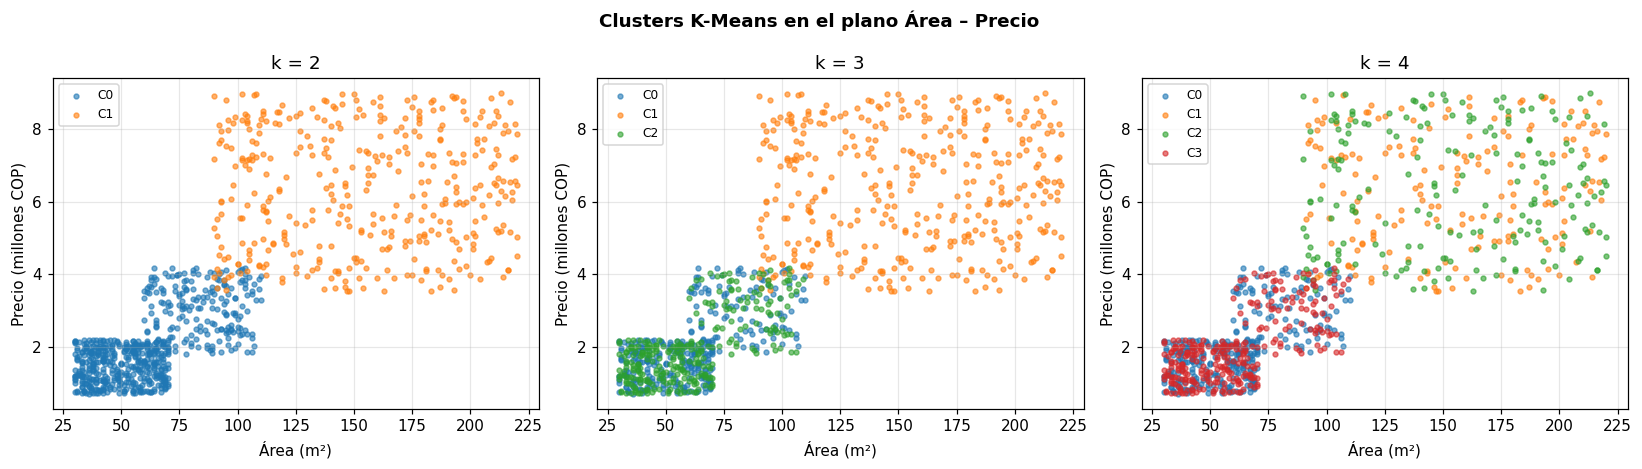

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (k, lab) in zip(ax, [(2, lab2), (3, lab3), (4, lab4)]):
    for c in sorted(set(lab)):
        s = df[lab == c]; a.scatter(s.Area_m2, s.Precio_arriendo / 1e6, s=10, alpha=0.6, label=f"C{c}")
    a.set_title(f"k = {k}"); a.set_xlabel("Área (m²)"); a.set_ylabel("Precio (millones COP)"); a.legend(fontsize=8)
fig.suptitle("Clusters K-Means en el plano Área – Precio", fontweight="bold")
guardar("04_kmeans_area_precio")

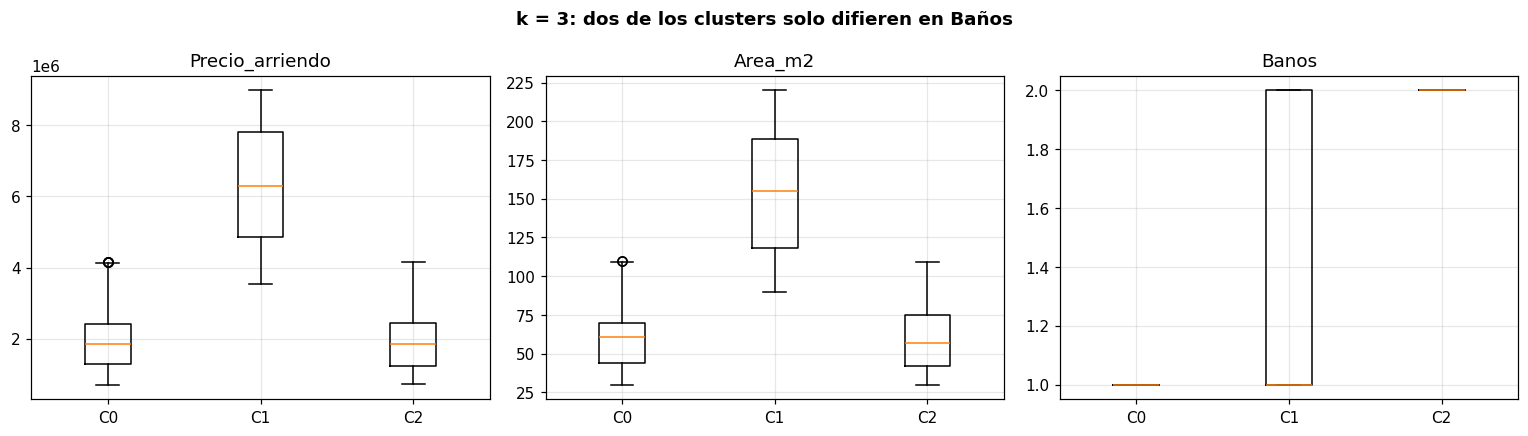

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, var in zip(ax, ["Precio_arriendo", "Area_m2", "Banos"]):
    datos = [df.loc[lab3 == c, var] for c in range(3)]
    a.boxplot(datos, labels=[f"C{c}" for c in range(3)]); a.set_title(var)
fig.suptitle("k = 3: dos de los clusters solo difieren en Baños", fontweight="bold")
guardar("05_boxplots_k3")

In [17]:
resumen = pd.DataFrame({
    "k": [2, 3, 4],
    "silueta": [silhouette_score(X, l) for l in (lab2, lab3, lab4)],
    "davies_bouldin": [davies_bouldin_score(X, l) for l in (lab2, lab3, lab4)],
    "tamaños": [np.bincount(l).tolist() for l in (lab2, lab3, lab4)]}).set_index("k")
print("ARI entre la partición k=2 y el corte Estrato<=4 vs >=5:",
      round(adjusted_rand_score(lab2, (df.Estrato >= 5).astype(int)), 3))
resumen.round(3)

ARI entre la partición k=2 y el corte Estrato<=4 vs >=5: 1.0


,silueta,davies_bouldin,tamaños
k,,,
2,0.350,1.207,"[618, 382]"
3,0.255,1.539,"[326, 382, 292]"
4,0.222,1.851,"[326, 188, 194, 292]"


## 7. Validación con clustering jerárquico (Ward)

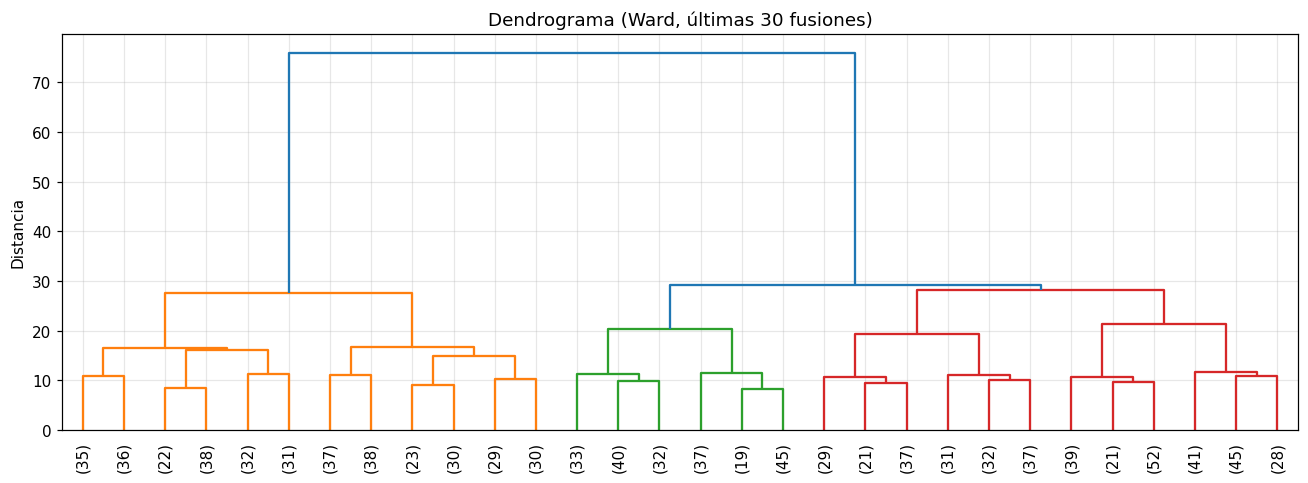

k=2: ARI K-Means vs Jerárquico = 0.996
k=3: ARI K-Means vs Jerárquico = 0.795
k=4: ARI K-Means vs Jerárquico = 0.564


In [18]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

Z = linkage(X, method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, color_threshold=Z[-2, 2])
plt.title("Dendrograma (Ward, últimas 30 fusiones)"); plt.ylabel("Distancia")
guardar("06_dendrograma")

for k, lab in [(2, lab2), (3, lab3), (4, lab4)]:
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    print(f"k={k}: ARI K-Means vs Jerárquico = {adjusted_rand_score(lab, hc):.3f}")

El dendrograma muestra un salto muy grande en la última fusión: hay **dos grupos naturales** claros. Ambos algoritmos coinciden casi totalmente con k = 2 (ARI ≈ 1), y cada vez menos al aumentar *k*, señal de que las particiones adicionales no son estructuras robustas.

## 8. Enfoque propuesto: segmentación con variables comerciales núcleo
Para obtener segmentos útiles para la inmobiliaria se repite K-Means usando solo las variables que definen el valor del inmueble (precio, área, habitaciones y estrato). Baños y antigüedad no aportan estructura y la localidad no diferencia a los inmuebles en este portafolio; se usan después para describir cada segmento.

In [19]:
NUCLEO = ["Precio_arriendo", "Area_m2", "Habitaciones", "Estrato"]
Xn = StandardScaler().fit_transform(df[NUCLEO])
for k in (2, 3, 4):
    l = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(Xn)
    print(f"k={k}: silueta = {silhouette_score(Xn, l):.3f}")

km_final = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xn)
d = df.assign(cluster=km_final.labels_)
orden = d.groupby("cluster").Precio_arriendo.mean().sort_values().index
nombres_seg = dict(zip(orden, ["Económico", "Intermedio", "Premium"]))
d["Segmento"] = d.cluster.map(nombres_seg)
perfil_final = d.groupby("Segmento")[NUM].mean().round(1).loc[["Económico", "Intermedio", "Premium"]]
perfil_final.insert(0, "n", d.Segmento.value_counts())
perfil_final["Estratos"] = d.groupby("Segmento").Estrato.apply(lambda s: f"{s.min()}–{s.max()}")
perfil_final["Precio_min"] = d.groupby("Segmento").Precio_arriendo.min(); perfil_final["Precio_max"] = d.groupby("Segmento").Precio_arriendo.max()
display(perfil_final)
display(pd.crosstab(d.Segmento, d.Estrato))

k=2: silueta = 0.611
k=3: silueta = 0.482
k=4: silueta = 0.427


,n,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,Estratos,Precio_min,Precio_max
Segmento,,,,,,,,,,
Económico,419,1469201.9,49.7,1.5,1.5,8.5,2.5,2–3,702480,2192854
Intermedio,209,3130625.3,85.4,2.5,1.5,8.6,4.1,4–6,1800798,5655479
Premium,372,6353200.0,156.1,4.0,1.5,8.3,5.5,5–6,3524810,8988836


Estrato,2,3,4,5,6
Segmento,,,,,
Económico,209,210,0,0,0
Intermedio,0,0,199,8,2
Premium,0,0,0,173,199


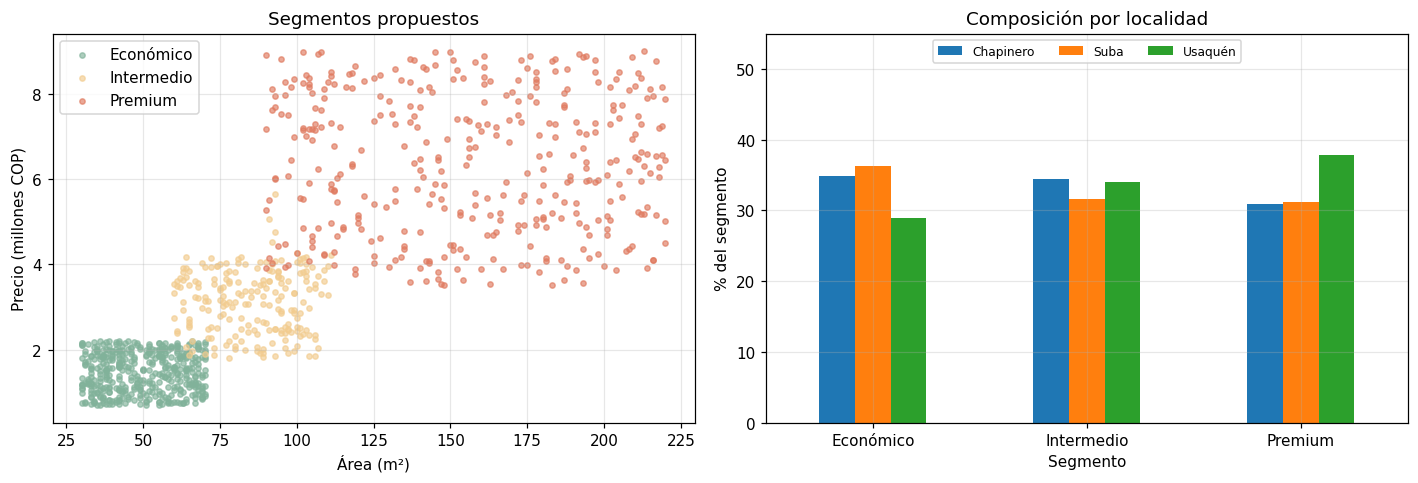

In [20]:
colores = {"Económico": "#81B29A", "Intermedio": "#F2CC8F", "Premium": "#E07A5F"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for seg, c in colores.items():
    s = d[d.Segmento == seg]
    ax[0].scatter(s.Area_m2, s.Precio_arriendo / 1e6, s=12, alpha=0.65, color=c, label=seg)
ax[0].set_xlabel("Área (m²)"); ax[0].set_ylabel("Precio (millones COP)"); ax[0].legend(); ax[0].set_title("Segmentos propuestos")
(pd.crosstab(d.Segmento, d.Localidad, normalize="index") * 100).loc[list(colores)].plot.bar(ax=ax[1], rot=0)
ax[1].set_ylim(0, 55); ax[1].legend(ncol=3, loc="upper center", fontsize=8)
ax[1].set_ylabel("% del segmento"); ax[1].set_title("Composición por localidad")
guardar("07_segmentos_propuestos")

## 9. Exportación de resultados (se conserva el identificador del inmueble)

In [21]:
salida = df[["ID_inmueble"] + NUM + CAT].copy()
salida["cluster_k2"] = lab2; salida["cluster_k3"] = lab3; salida["cluster_k4"] = lab4
salida["segmento_propuesto"] = d.Segmento
salida.to_csv(f"{RES_DIR}/inmuebles_segmentados.csv", index=False, encoding="utf-8-sig")
perfil_final.to_csv(f"{RES_DIR}/perfil_segmentos.csv", encoding="utf-8-sig")
salida.head(10)

,ID_inmueble,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,Localidad,Tipo_inmueble,cluster_k2,cluster_k3,cluster_k4,segmento_propuesto
0,I1,1413951,69,2,2,11,2,Suba,Apto,0,2,3,Económico
1,I2,1006165,39,1,2,10,2,Chapinero,Casa,0,2,3,Económico
2,I3,8570904,142,5,1,8,5,Usaquén,ApartaEstudio,1,1,2,Premium
3,I4,3678698,62,3,1,12,4,Suba,Apto,0,0,0,Intermedio
4,I5,875729,58,1,1,12,3,Chapinero,Casa,0,0,0,Económico
5,I6,2836207,76,3,1,8,4,Usaquén,ApartaEstudio,0,0,0,Intermedio
6,I7,3808969,80,2,2,7,4,Suba,Apto,0,2,3,Intermedio
7,I8,8338969,204,4,1,12,6,Chapinero,Casa,1,1,2,Premium
8,I9,8336930,99,4,2,7,5,Usaquén,ApartaEstudio,1,1,1,Premium
9,I10,5758932,111,5,1,6,5,Suba,Apto,1,1,2,Premium


## 10. Conclusiones
- Con todas las variables, la estructura natural del portafolio tiene **dos grupos** (silueta máxima con k = 2, confirmada por el dendrograma): inmuebles de estrato 2–4 (~61 m², ~$2,0 M) y de estrato 5–6 (~155 m², ~$6,3 M).
- Con k = 3 y k = 4 los grupos extra se forman por el número de baños, no por diferencias comerciales relevantes.
- Usando solo las variables comerciales núcleo, K-Means con k = 3 encuentra los segmentos **Económico, Intermedio y Premium** con buena separación (silueta ≈ 0,48), que es la segmentación más útil para la inmobiliaria.
- La localidad no diferencia los segmentos: los tres se distribuyen casi por igual en Suba, Chapinero y Usaquén.